Importing libraries:

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Load Dataset:

In [2]:
dataset=pd.read_csv("Mall_Customers.csv")

Features Split:

In [3]:
X=dataset.iloc[:,[3,4]].values

Standard Scaler:

In [4]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
X_scaled=sc.fit_transform(X)

Find the Best n_clusters using Silhouette Score:

In [5]:
from sklearn.metrics import silhouette_score
from sklearn.cluster import SpectralClustering

for i in range(2, 10):

    model = SpectralClustering(
        n_clusters=i,
        affinity='nearest_neighbors',
        gamma=1.0,
        assign_labels='kmeans',
        n_neighbors=15,
        random_state=42
    )

    label = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, label)

    print(f"Clusters: {i}")
    print(f"Silhouette Score: {score:.4f}")
    print("-------------------")

Clusters: 2
Silhouette Score: 0.3842
-------------------
Clusters: 3
Silhouette Score: 0.4666
-------------------
Clusters: 4
Silhouette Score: 0.4942
-------------------
Clusters: 5
Silhouette Score: 0.5420
-------------------
Clusters: 6
Silhouette Score: 0.4540
-------------------
Clusters: 7
Silhouette Score: 0.4091
-------------------
Clusters: 8
Silhouette Score: 0.4029
-------------------
Clusters: 9
Silhouette Score: 0.3670
-------------------


Train a Model:

In [6]:
from sklearn.cluster import SpectralClustering
cluster=SpectralClustering(
        n_clusters=5,
        affinity='nearest_neighbors',
        gamma=1.0,
        assign_labels='kmeans',
        n_neighbors=15,
        random_state=42
    )
labels=cluster.fit_predict(X_scaled)

Display the Cluster lables:

In [7]:
labels

array([3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4,
       3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 2,
       3, 4, 2, 2, 3, 3, 2, 2, 2, 2, 2, 3, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 1, 0, 1, 0, 1,
       2, 1, 0, 1, 0, 1, 0, 1, 0, 1, 2, 1, 0, 1, 2, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1], dtype=int32)

Create a DataFrame to Existing Dataset:

In [8]:
Clustered_Dataset=pd.DataFrame(dataset)

Add Labels to the Existing Dataset:

In [9]:
Clustered_Dataset["Clustered_Group"]=labels
Clustered_Dataset

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100),Clustered_Group
0,1,Male,19,15,39,3
1,2,Male,21,15,81,4
2,3,Female,20,16,6,3
3,4,Female,23,16,77,4
4,5,Female,31,17,40,3
...,...,...,...,...,...,...
195,196,Female,35,120,79,1
196,197,Female,45,126,28,0
197,198,Male,32,126,74,1
198,199,Male,32,137,18,0


Plot the Cluster's Graph:

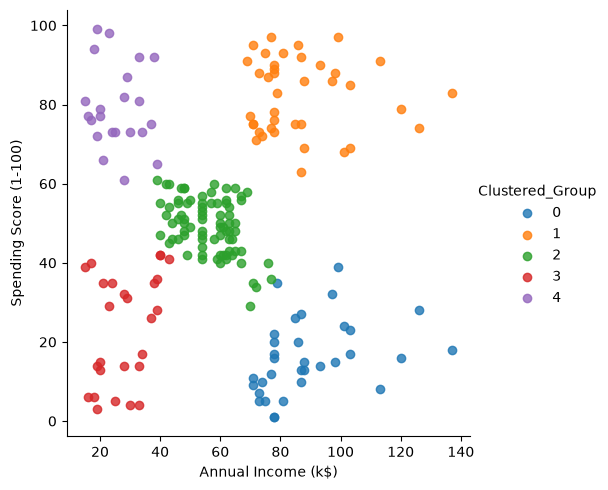

In [10]:
import seaborn as sns
facet=sns.lmplot(data=Clustered_Dataset,x=Clustered_Dataset.columns[3],y=Clustered_Dataset.columns[4],hue=Clustered_Dataset.columns[5],
                legend=True,fit_reg=False)
facet

Evaluation Metrics:

In [11]:
from sklearn.metrics import silhouette_score
score=silhouette_score(X_scaled,labels)
print(f"The Model Segregated score(-1 to +1) :{score:.4f}")

The Model Segregated score(-1 to +1) :0.5420


Average Annual Income and Spending Score by Cluster for Final Understanding:

In [12]:
cluster_profile=Clustered_Dataset.groupby('Clustered_Group')[
    ['Annual Income (k$)','Spending Score (1-100)']
    ].mean()
print(cluster_profile)

                 Annual Income (k$)  Spending Score (1-100)
Clustered_Group                                            
0                         89.090909               16.181818
1                         86.538462               82.128205
2                         56.287500               49.387500
3                         28.000000               23.307692
4                         25.727273               79.363636


Count the Dataset Lables Based on Uniques:

In [13]:
print(Clustered_Dataset['Clustered_Group'].value_counts())

Clustered_Group
2    80
1    39
0    33
3    26
4    22
Name: count, dtype: int64
